# Cloud–Edge Visualization · Interactive Lab & Paper Figures

One notebook for the **current English cloud–edge interaction lab** and the **existing publication PNGs**. Run the cells in order. No helper modules are imported or created, no figures are regenerated, and no experiments or cloud jobs are started.

**Quick navigation:** [Paper figures](#paper-figures) · [Interactive lab](#interactive-lab) · [Preview lifecycle](#preview-lifecycle). Figure captions retain their original snapshot and source IDs; the frontend's historical replay supplement remains a separate recorded batch.

Predicted risk is not audited risk. A completed computation or transfer is not algorithm acceptance. Missing costs and evidence stay missing; rounds from one training seed do not become independent replicates.

## 1 · Workspace and explicit presentation controls

Use the project's Python kernel with IPython, pandas and psutil. The existing built frontend is read from `frontend/dist/`; if frontend sources or public data change, rebuild separately with `cd frontend` and `npm run build`. Packages are never installed by this notebook.

On Windows, section 6 starts the existing Vite preview through a bounded PowerShell process, or embeds the explicitly configured `FRONTEND_URL`. Rerunning in the same kernel reuses the live preview. The preview stops at lease expiry; the kernel may also stop its children during shutdown. Only frontend preview logs are written; images, manifests, snapshots and experiment files are read-only.

In [1]:
from pathlib import Path, PurePosixPath
import json
from html import escape
from IPython.display import Image, FileLink, HTML, IFrame, display

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'frontend/package.json').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the RL_project directory')
FIGURE_IDS = []  # Empty: all registered figures; e.g. ['decision_atlas_1'].
FIGURE_DISPLAY_WIDTH = 1000
FRONTEND_URL = ''  # Optional URL of an already running local frontend.
FRONTEND_HEIGHT = 1050
START_PREVIEW = True
PREVIEW_LEASE_SECONDS = 1800
STOP_PREVIEW = False  # Stop this kernel's owned preview in section 7.

print('Project:', PROJECT_ROOT)
print('Read-only images and experiment records; no training or cloud execution')

Project: c:\DevSpace\PyDevspace\RL\RL_project
Read-only images and experiment records; no training or cloud execution


## 2 · Read the existing snapshot and historical replay supplement

Read the current index-registered snapshot and the frontend-owned historical replay JSON directly with `pathlib` and `json`. They are not merged or rewritten by the notebook. A missing file is reported, never replaced by an automatic export.

The historical seven-policy supplement enables playback, not a current-batch or formal-acceptance claim. The interactive lab applies its own existing strict joins and coverage labels.

In [2]:
snapshot = historical = None
data_root = PROJECT_ROOT / 'frontend/public/data'
index_path = data_root / 'index.json'
if index_path.is_file():
    index = json.loads(index_path.read_text(encoding='utf-8'))
    entries = [e for e in index.get('snapshots', []) if e['snapshot_id'] == index.get('current_snapshot')]
    if index.get('schema_version') != 'results_index_v1' or len(entries) != 1:
        raise ValueError('Unsupported or ambiguous snapshot index')
    relative = PurePosixPath(entries[0]['path'])
    if relative.is_absolute() or any(p == '..' or ':' in p or '\\' in p for p in relative.parts):
        raise ValueError('Unconfined snapshot path')
    snapshot_path = (data_root / str(relative)).resolve()
    if not snapshot_path.is_relative_to(data_root.resolve()) or snapshot_path.stat().st_size > 64 * 1024 * 1024:
        raise ValueError('Invalid snapshot path or size')
    snapshot = json.loads(snapshot_path.read_text(encoding='utf-8'))
    if snapshot.get('schema_version') != 'results_visualization_v1' or snapshot.get('snapshot_id') != index['current_snapshot']:
        raise ValueError('Snapshot/index identity mismatch')
    print('Snapshot:', snapshot['snapshot_id'], '| Runs:', len(snapshot['runs']))
else:
    print('No registered snapshot; no export was started')
replay_path = PROJECT_ROOT / 'frontend/public/replays/native-validation-v1.json'
if replay_path.is_file():
    historical = json.loads(replay_path.read_text(encoding='utf-8'))
    if historical.get('schema_version') != 'frontend_replays_v1':
        raise ValueError('Unsupported historical replay supplement')
    print('Historical supplement:', len(historical['runs']), 'runs |', sum(len(r['metrics']) for r in historical['runs']), 'recorded rounds')

Snapshot: 20261010T210356474304Z-8bac069e9628 | Runs: 72
Historical supplement: 7 runs | 209 recorded rounds


## 3 · Inspect evidence before interpreting plots

The table preserves batch, split, seed, phase, checkpoint budget and risk measure. Original snapshots and historical playback are labeled separately. No ranking, statistical pooling or acceptance calculation is performed.

In [3]:
import pandas as pd

rows = []
for batch, recorded in [('snapshot', snapshot), ('historical replay', historical)]:
  for run in (recorded or {}).get('runs', []):
    rows.append({
        'batch': batch,
        'method': run['arm'] or run['method'], 'phase': run['phase'], 'stage': run['stage'],
        'split': run['partition'], 'train_seed': run['train_seed'], 'eval_seed': run['eval_seed'],
        'checkpoint': run['config_summary'].get('checkpoint_step'),
        'new_interactions': run['budget']['new_interactions'],
        'cumulative_interactions': run['budget']['cumulative_interactions'],
        'accuracy': run['summary'].get('validation_accuracy'),
        'simulated_time_s': run['summary'].get('elapsed_seconds'),
        'simulated_energy_J': run['summary'].get('energy_joules'),
        'risk_measure': run['risk_measurement'], 'verification': run['status'].get('verification'),
        'run_id': run['run_id'],
    })
display(pd.DataFrame(rows))

,batch,method,phase,stage,split,train_seed,eval_seed,checkpoint,new_interactions,cumulative_interactions,accuracy,simulated_time_s,simulated_energy_J,risk_measure,verification,run_id
0,snapshot,N1,pilot,train_policy,train,96101.0,NaN,NaN,500.0,500.0,NaN,NaN,NaN,predicted_risk,verified,ablation-n-7e21a45eb4e542529462c361acf7dc7a-N1...
1,snapshot,N3,pilot,train_policy,train,96101.0,NaN,NaN,500.0,500.0,NaN,NaN,NaN,predicted_risk,verified,ablation-n-7e21a45eb4e542529462c361acf7dc7a-N3...
2,snapshot,N1,continue,train_policy,train,96101.0,NaN,NaN,700.0,1200.0,NaN,NaN,NaN,predicted_risk,verified,ablation-n-7e21a45eb4e542529462c361acf7dc7a-N1...
3,snapshot,N1,continue,validate,validation,96101.0,96201.0,NaN,30.0,30.0,0.747082,5.511476,46.019760,predicted_risk,verified,ablation-n-7e21a45eb4e542529462c361acf7dc7a-N1...
4,snapshot,N3,continue,train_policy,train,96101.0,NaN,NaN,700.0,1200.0,NaN,NaN,NaN,predicted_risk,verified,ablation-n-7e21a45eb4e542529462c361acf7dc7a-N3...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,historical replay,pqn,historical-validation-20261008,validate,validation,101.0,201.0,NaN,NaN,NaN,0.759060,4.614949,31.899269,predicted_exposure_risk,NaN,validate-pqn-s201-b7e57a65e40b
75,historical replay,metacs,historical-validation-20261008,validate,validation,NaN,201.0,NaN,NaN,NaN,0.759214,4.204313,27.068038,predicted_exposure_risk,NaN,validate-metacs-s201-69431882a057
76,historical replay,fixed,historical-validation-20261008,validate,validation,NaN,201.0,NaN,NaN,NaN,0.758907,6.975560,45.042581,predicted_exposure_risk,NaN,validate-fixed-s201-70cfbd77561e
77,historical replay,time_greedy,historical-validation-20261008,validate,validation,NaN,201.0,NaN,NaN,NaN,0.759674,3.794031,26.148410,predicted_exposure_risk,NaN,validate-time_greedy-s201-4250f5953f11


## 4 · Read the existing publication manifest

The notebook reads `figure_assets/manifest.json` and its registered PNGs from `figure_assets/main/`. It never imports a renderer or changes resolution, palette, layout or captions.

If the figure manifest belongs to another snapshot, the images remain available with an explicit mismatch notice; they are not presented as current-snapshot evidence.

Set `FIGURE_IDS` in section 1 to show selected images, or leave it empty to browse all registered figures.

In [ ]:
asset_root = PROJECT_ROOT / 'figure_assets'
manifest_path = asset_root / 'manifest.json'
manifest = None
if manifest_path.is_file():
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    if manifest.get('schema_version') != 'figure_manifest_v1':
        raise ValueError('Unsupported figure manifest')
    print('Figure snapshot:', manifest['snapshot_id'], '| Registered PNGs:', len(manifest['figures']))
    if snapshot is None or manifest['snapshot_id'] != snapshot['snapshot_id']:
        print('NOTICE: figure and frontend snapshot IDs do not match; keep these evidence batches separate')
else:
    print('No figure manifest; existing files were not regenerated')

<a id="paper-figures"></a>
## 5 · Paper gallery and provenance

These are the actual existing PNG assets, independent of the interactive frontend. Open the caption/provenance details under each image for its evidence scope, accessibility description and source run IDs. Display width changes only the notebook preview, not the image file.

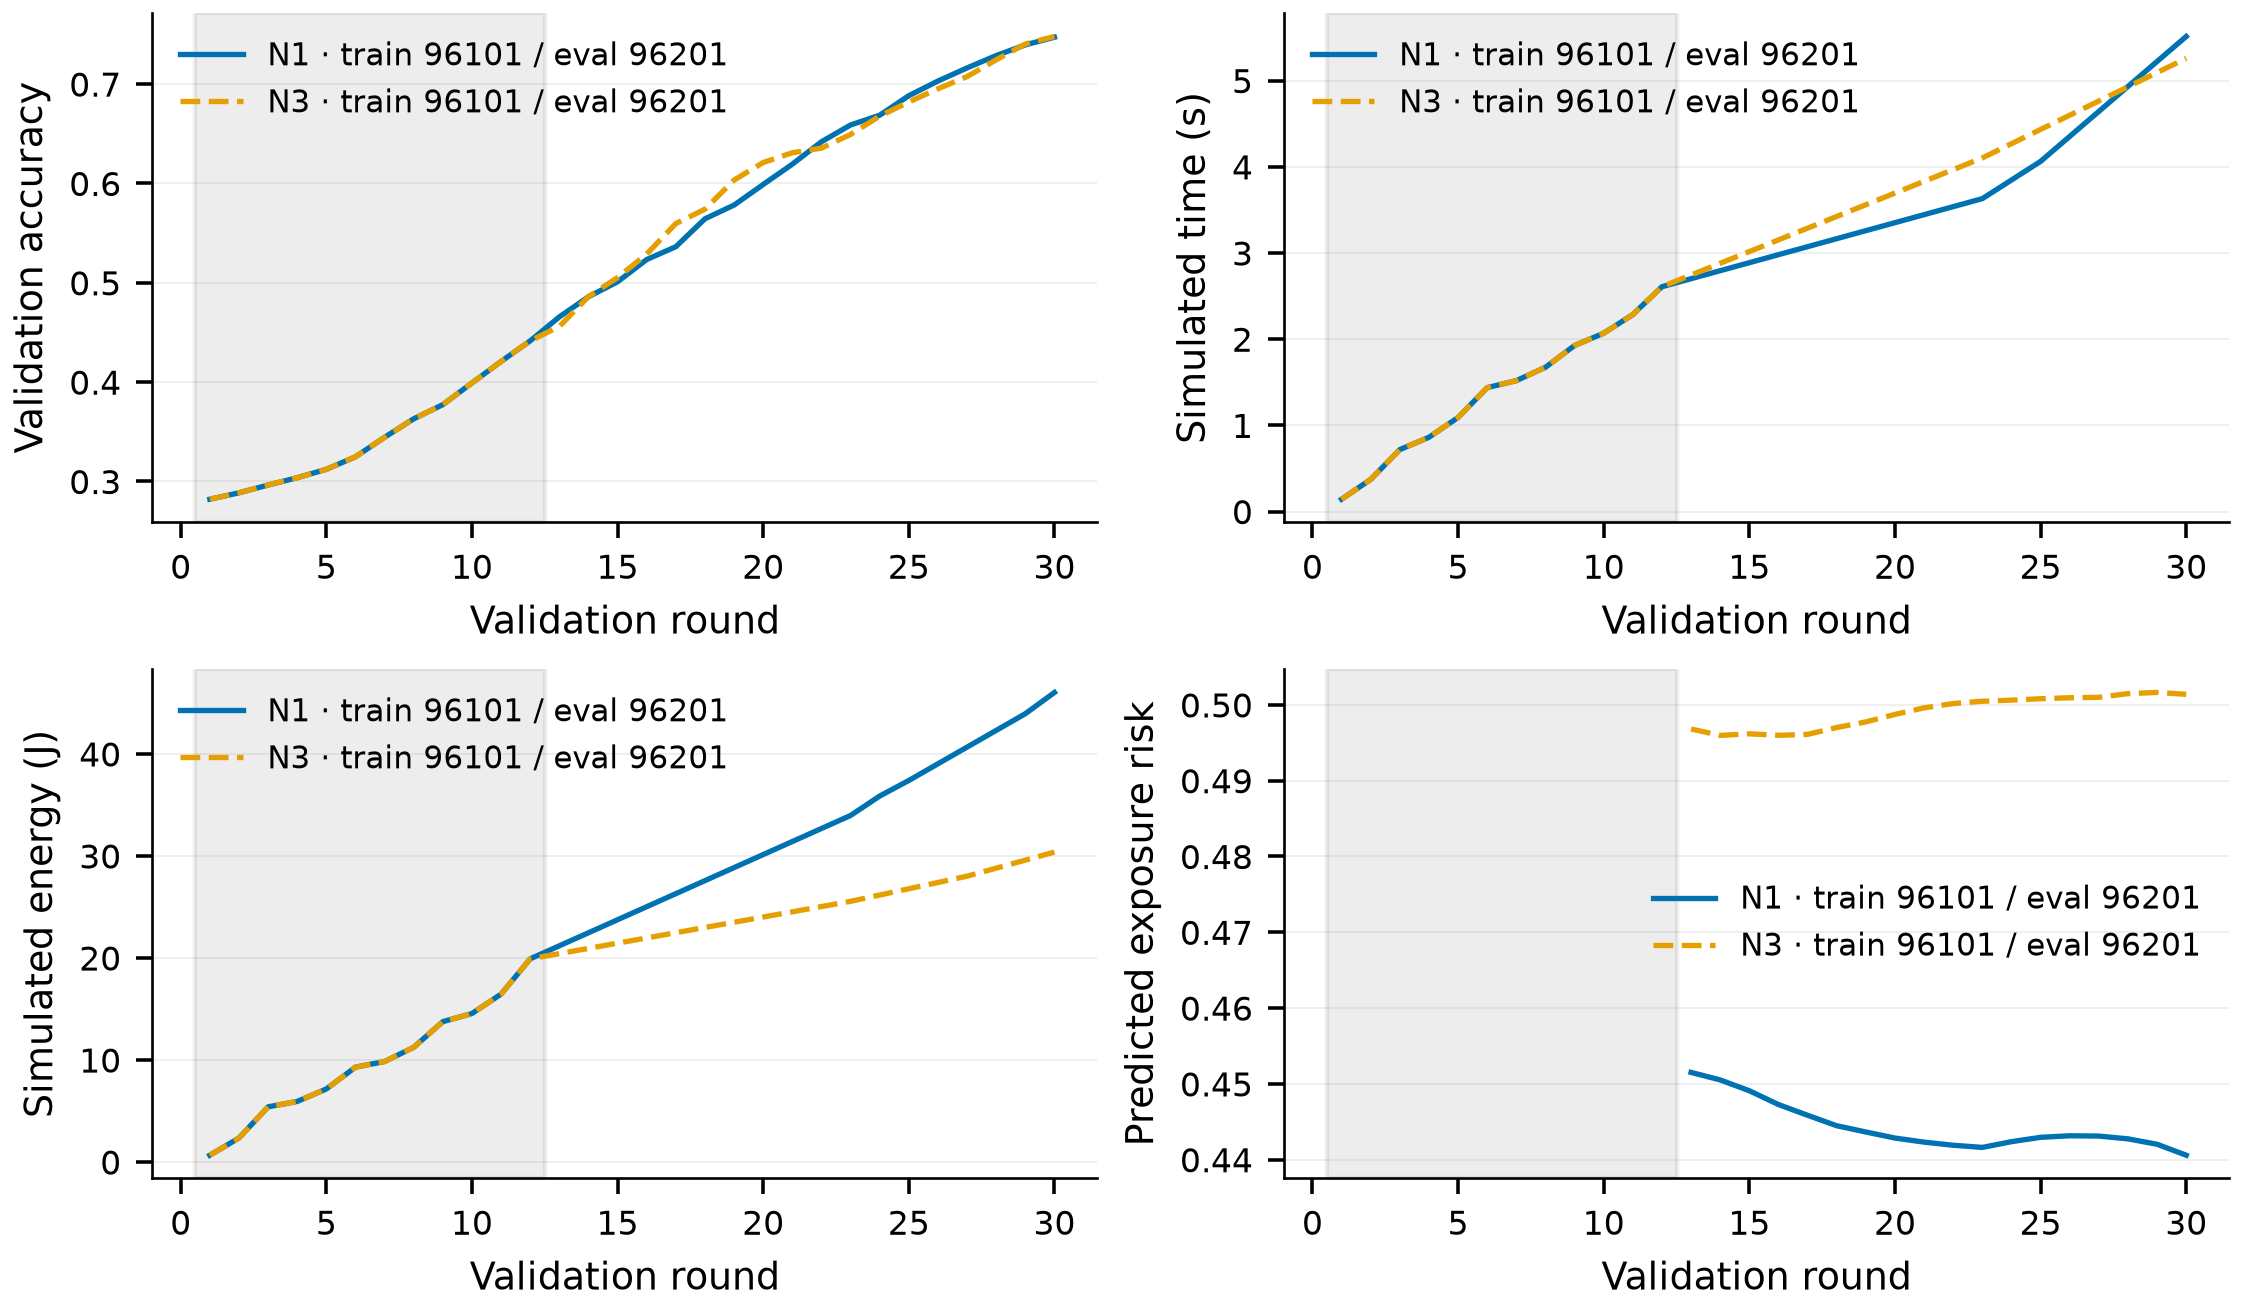

c:\DevSpace\PyDevspace\RL\RL_project\figure_assets\main\learning_progress.png

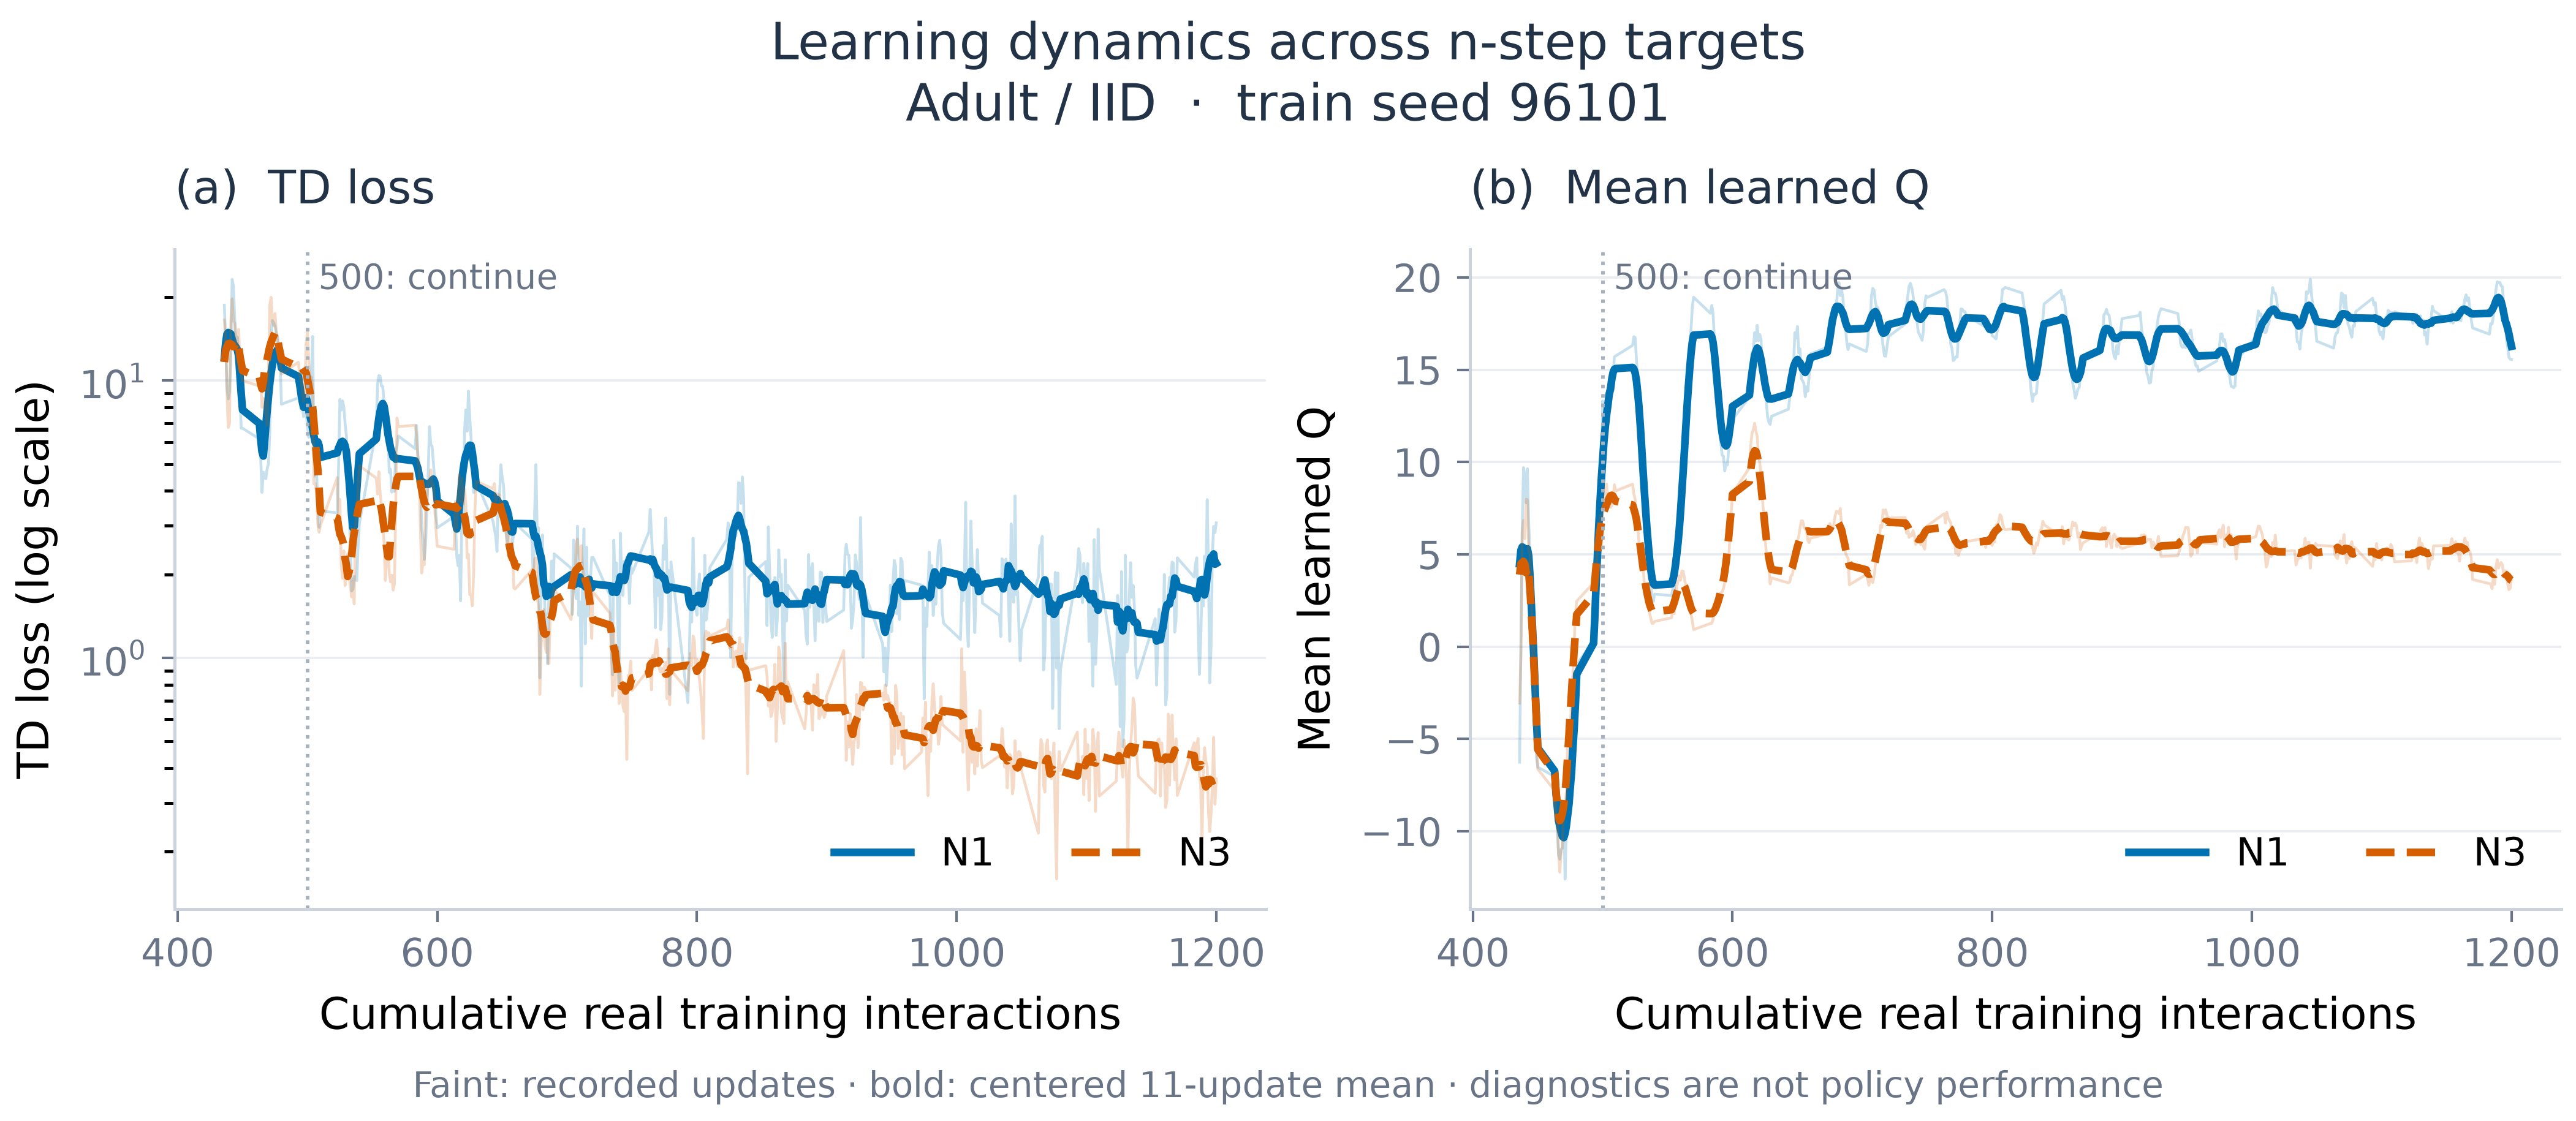

c:\DevSpace\PyDevspace\RL\RL_project\figure_assets\main\training_diagnostics_1.png

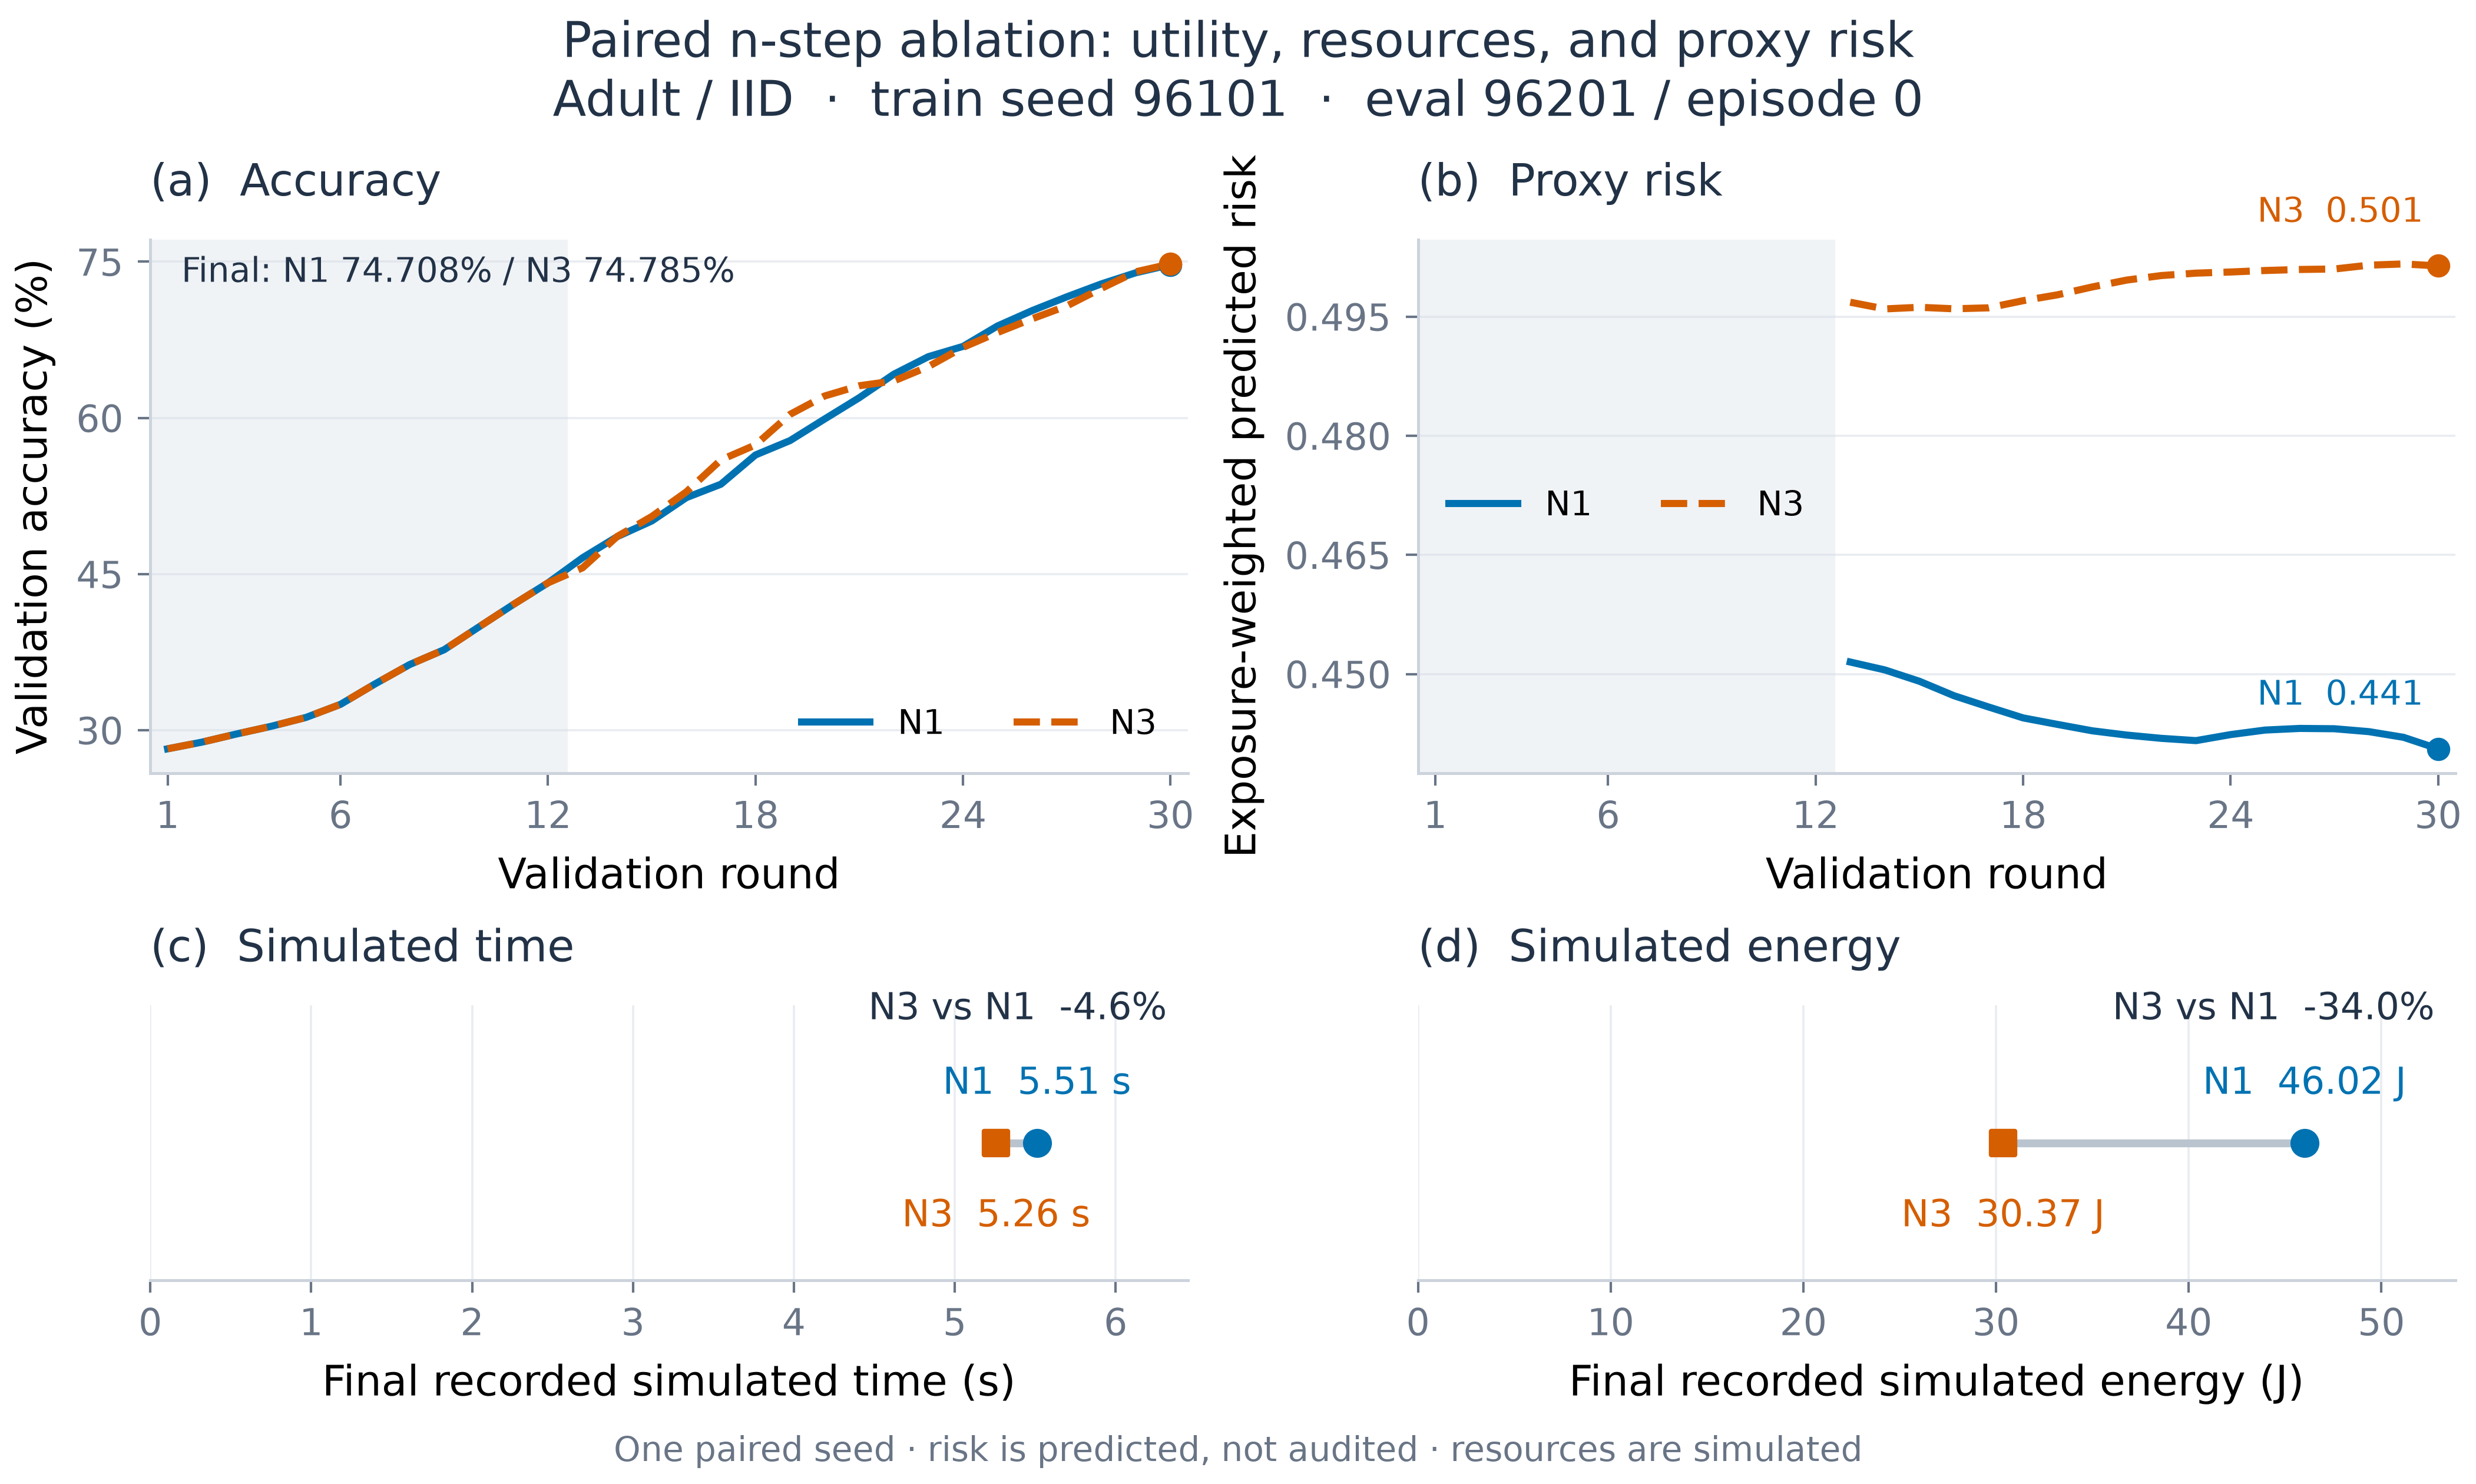

c:\DevSpace\PyDevspace\RL\RL_project\figure_assets\main\paired_ablation_1.png

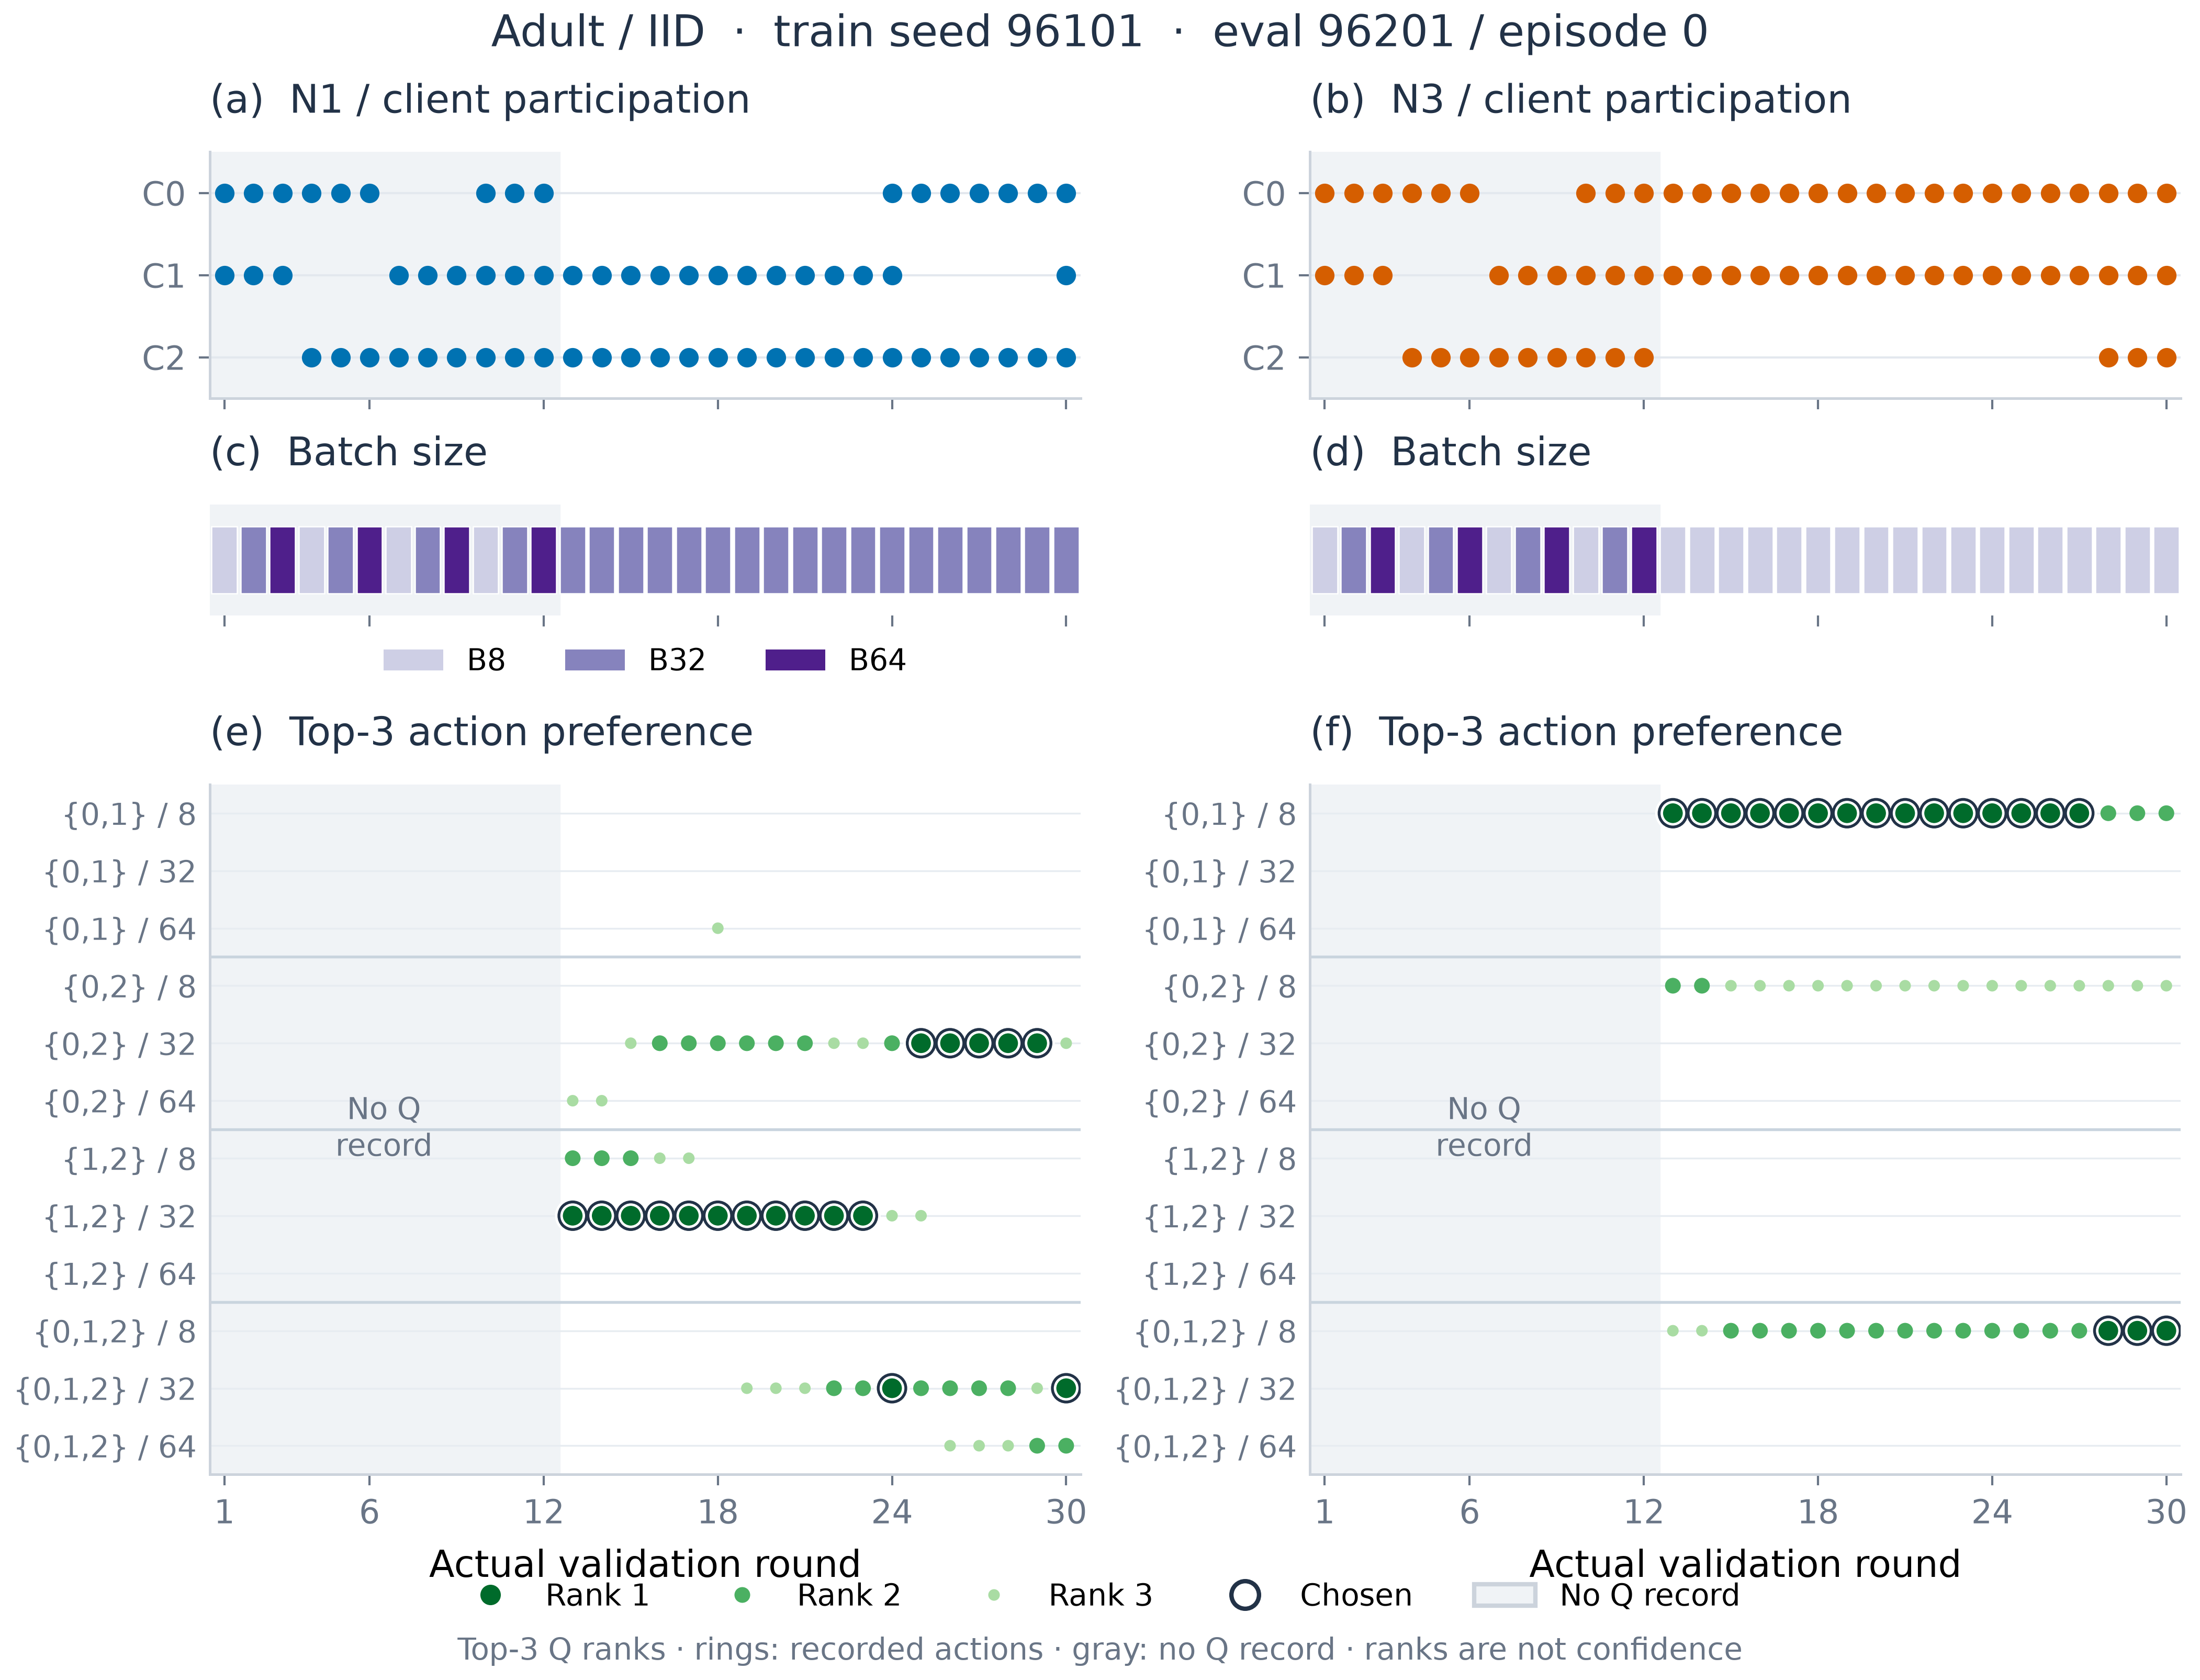

c:\DevSpace\PyDevspace\RL\RL_project\figure_assets\main\decision_atlas_1.png

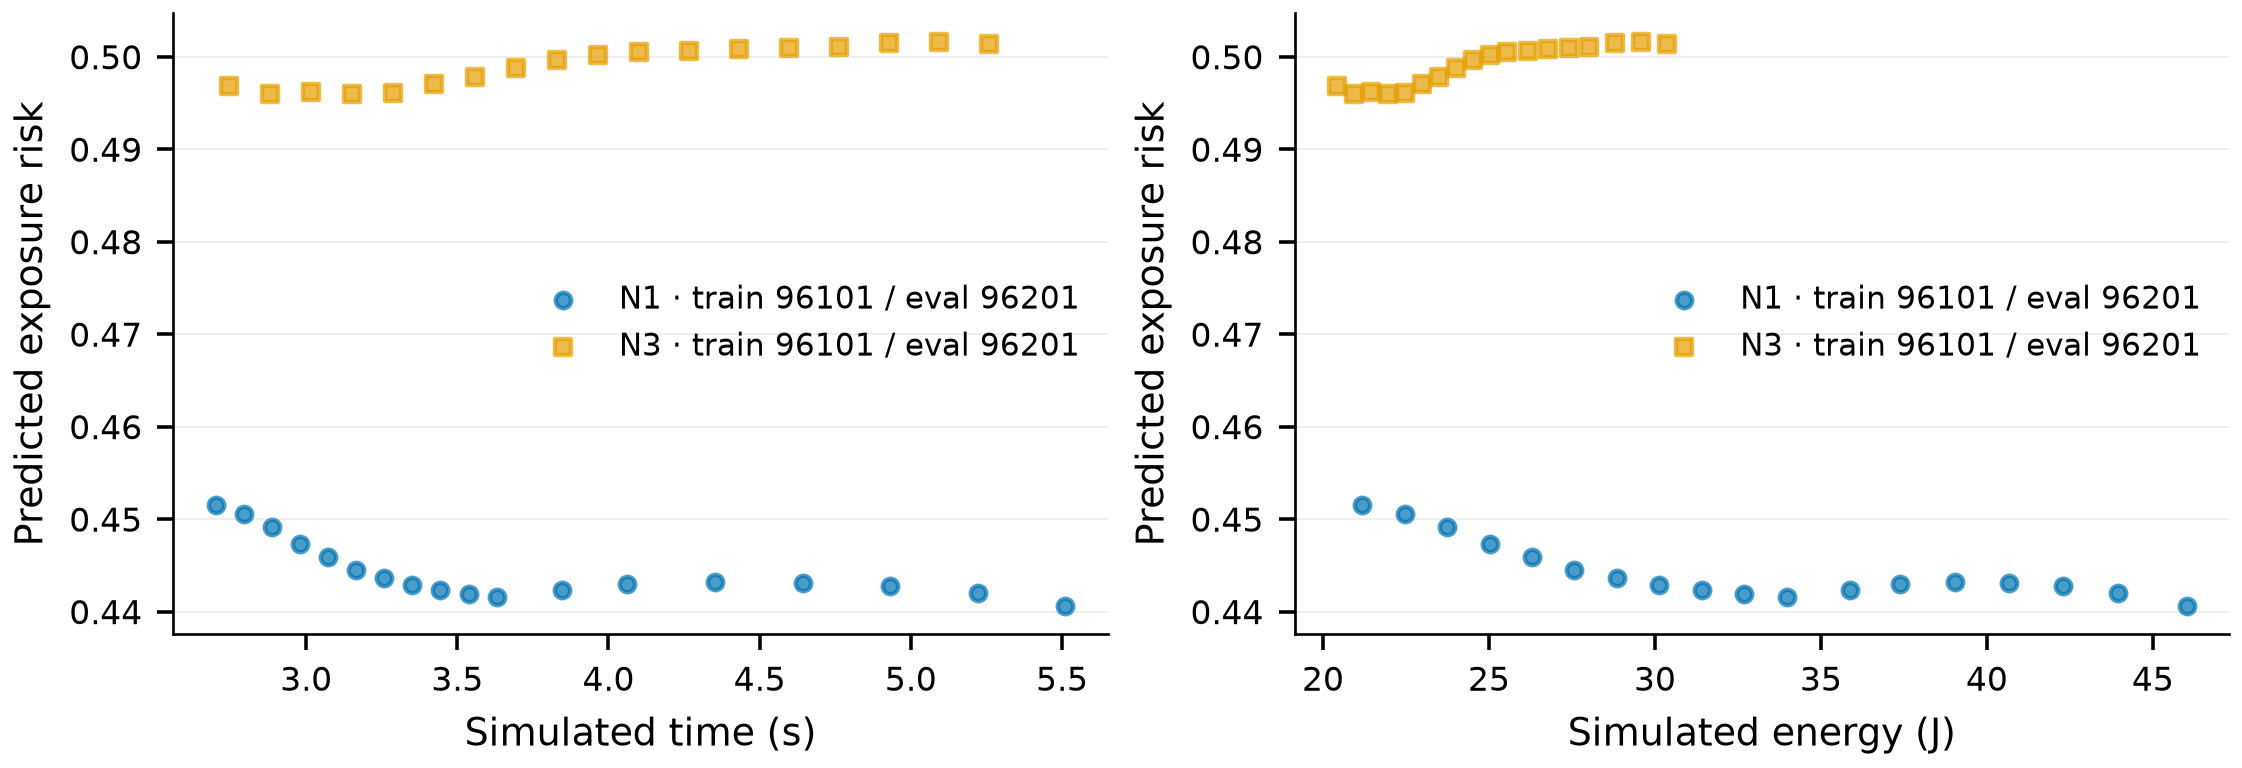

c:\DevSpace\PyDevspace\RL\RL_project\figure_assets\main\resource_risk_1.png

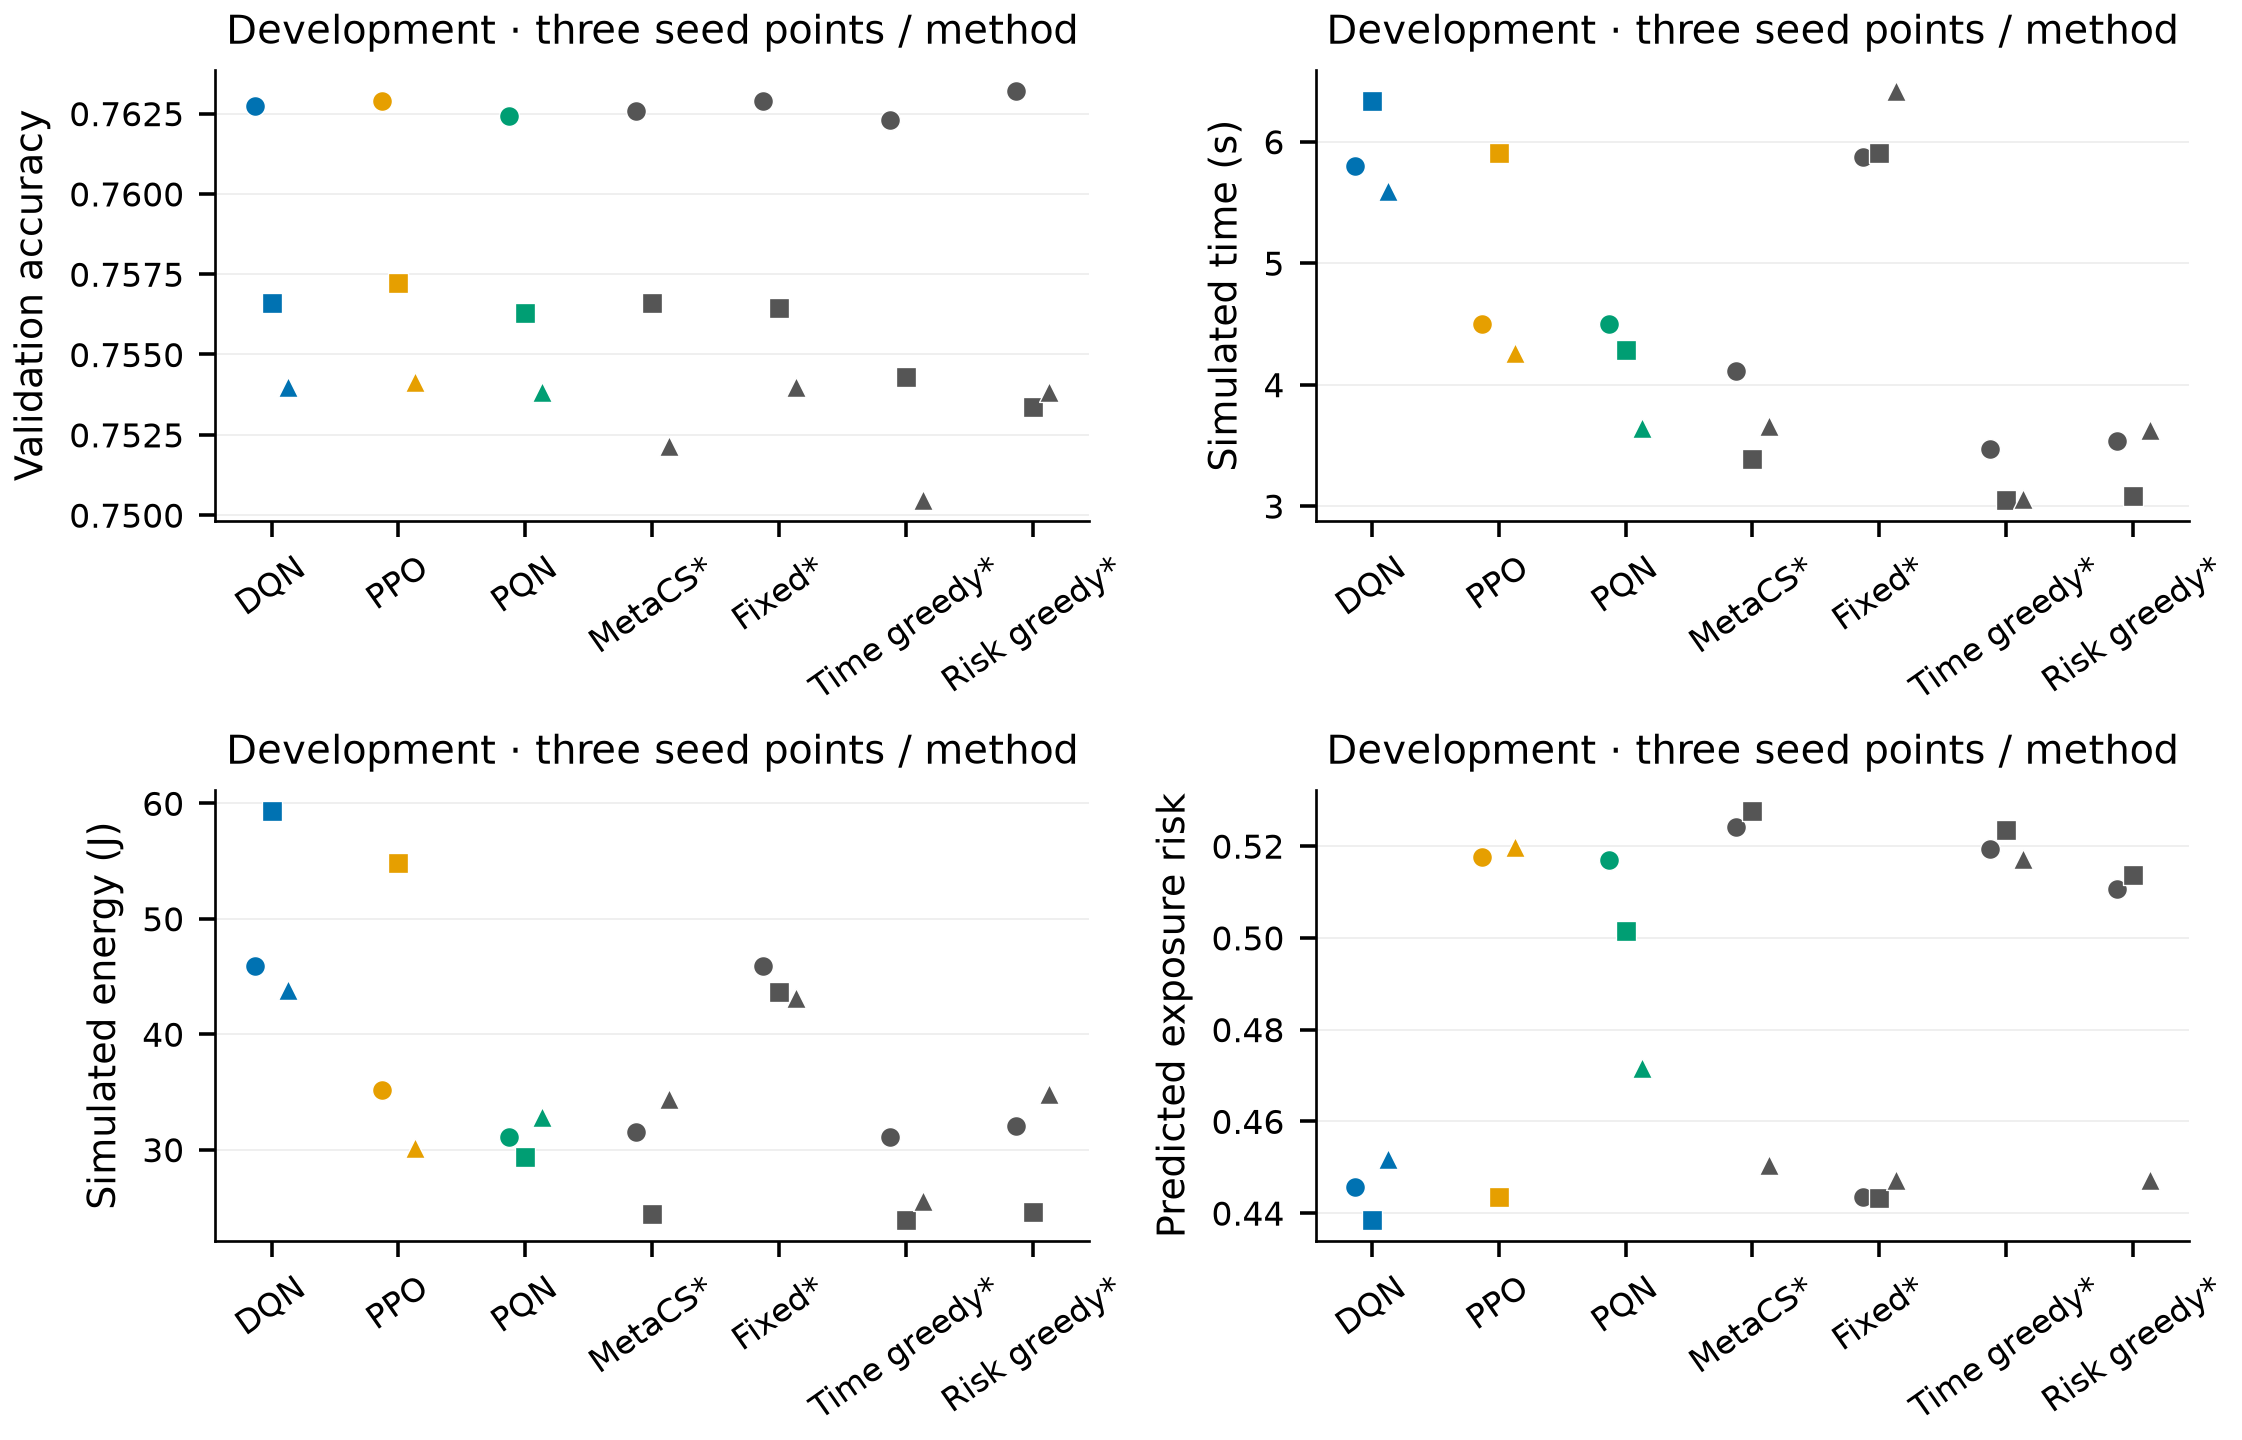

c:\DevSpace\PyDevspace\RL\RL_project\figure_assets\main\method_comparison.png

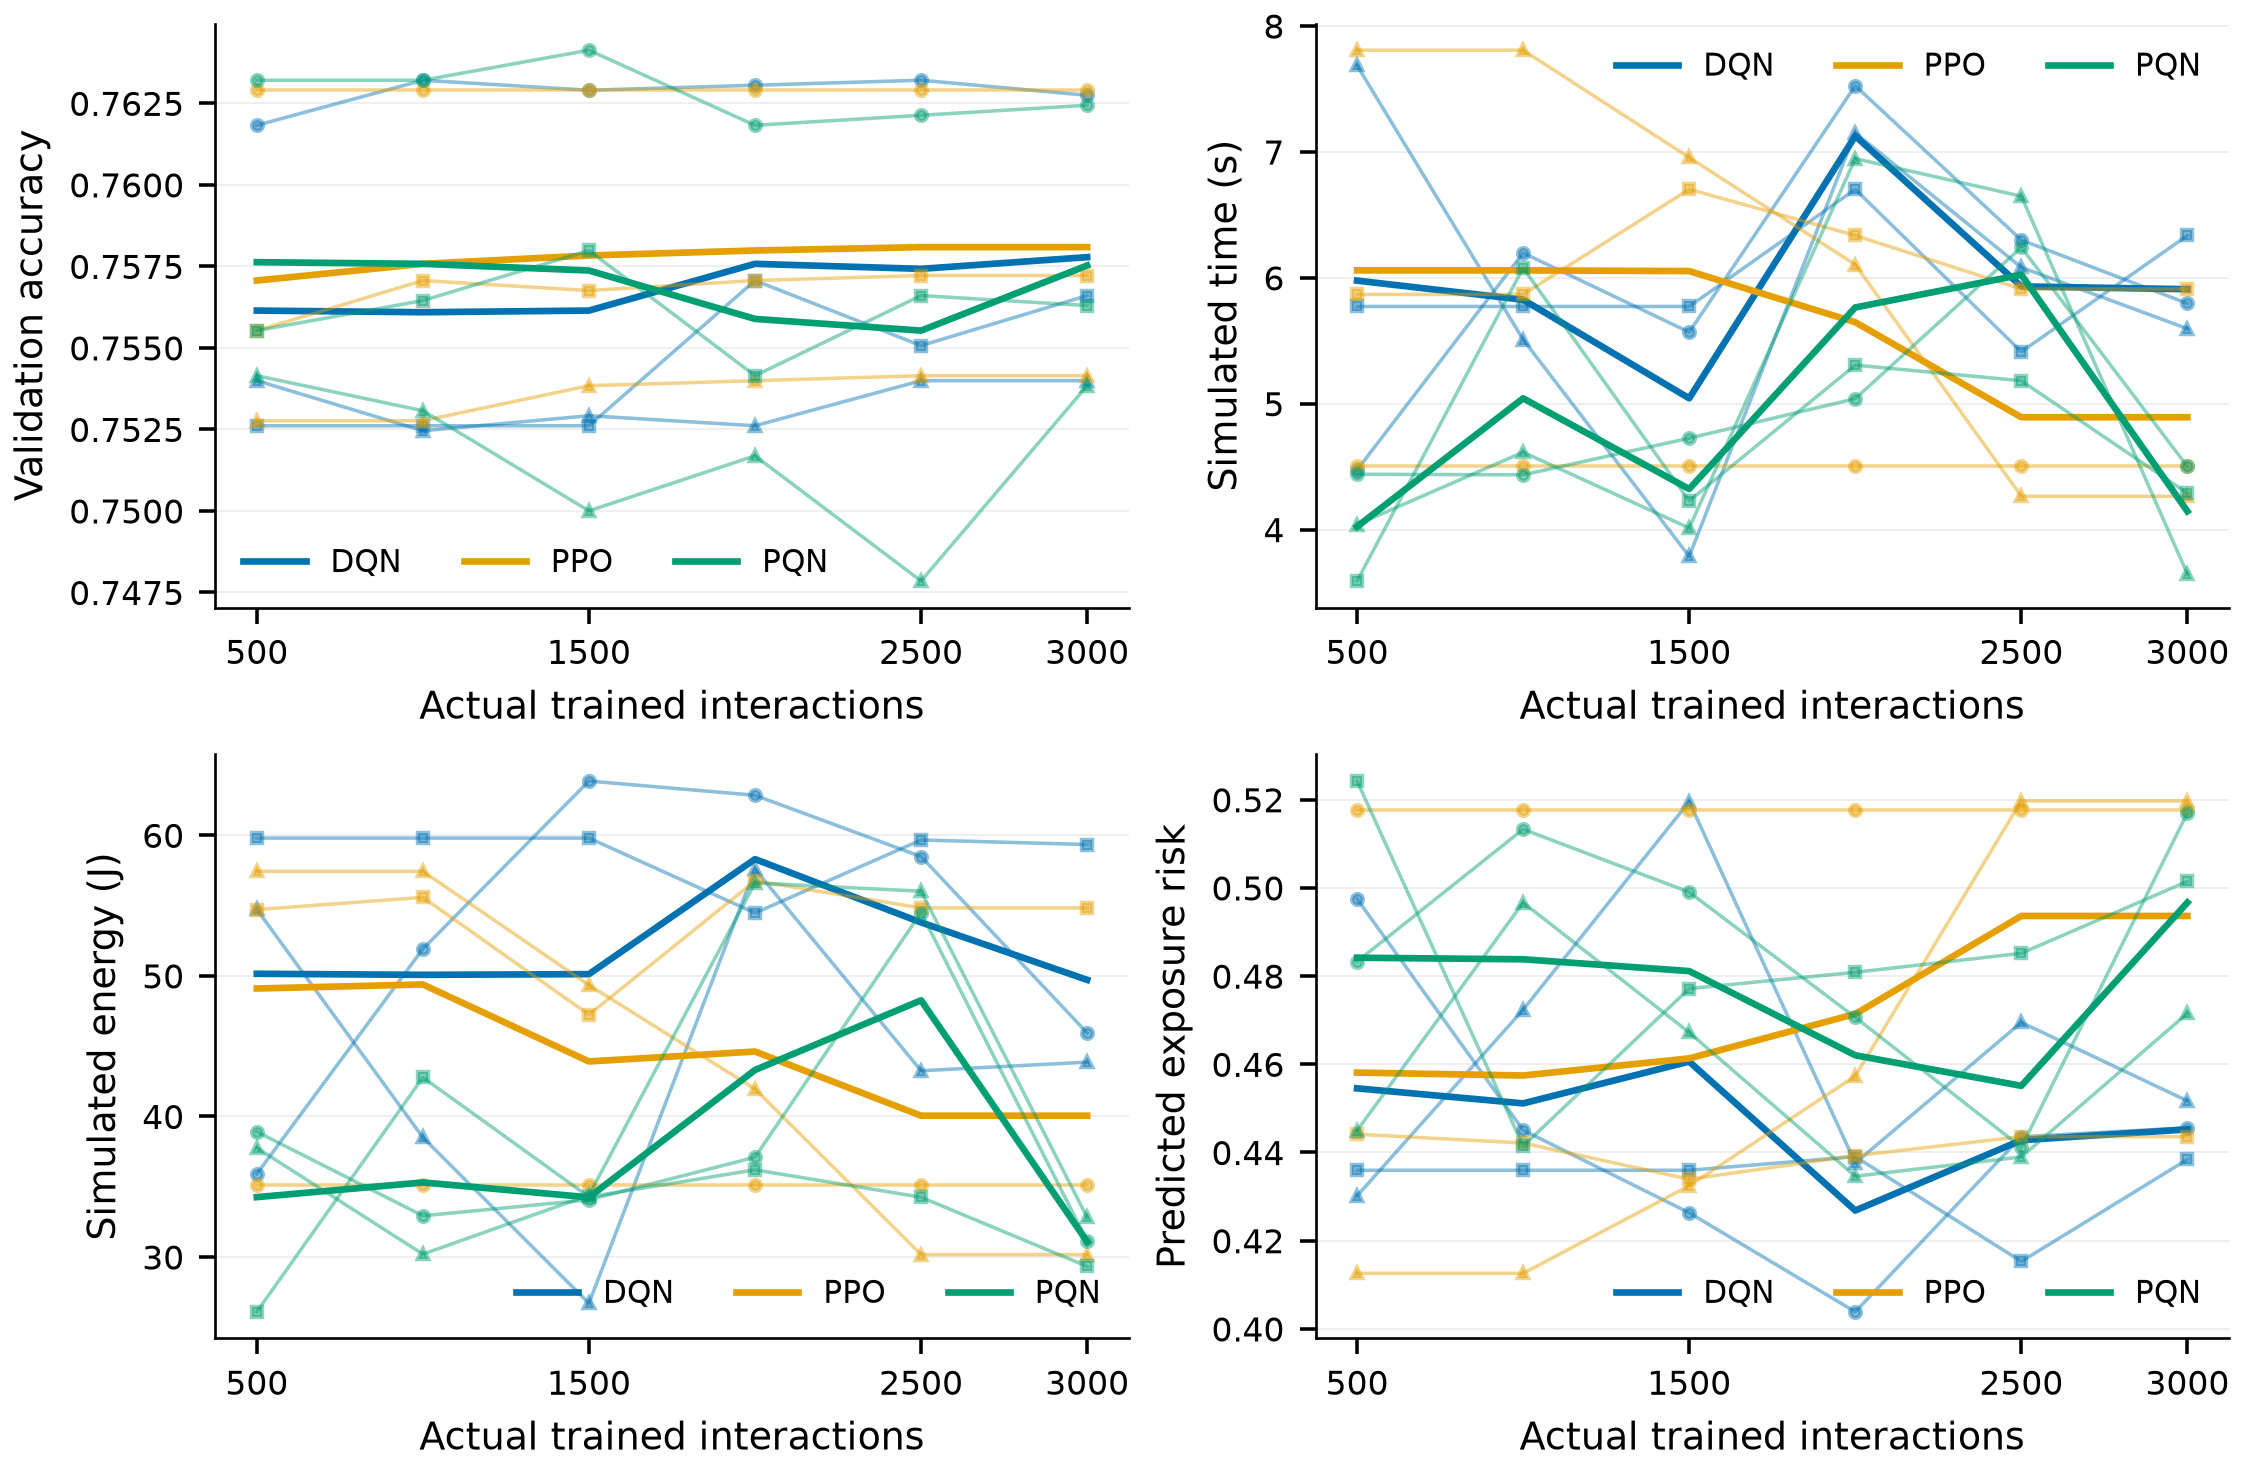

c:\DevSpace\PyDevspace\RL\RL_project\figure_assets\main\checkpoint_learning.png

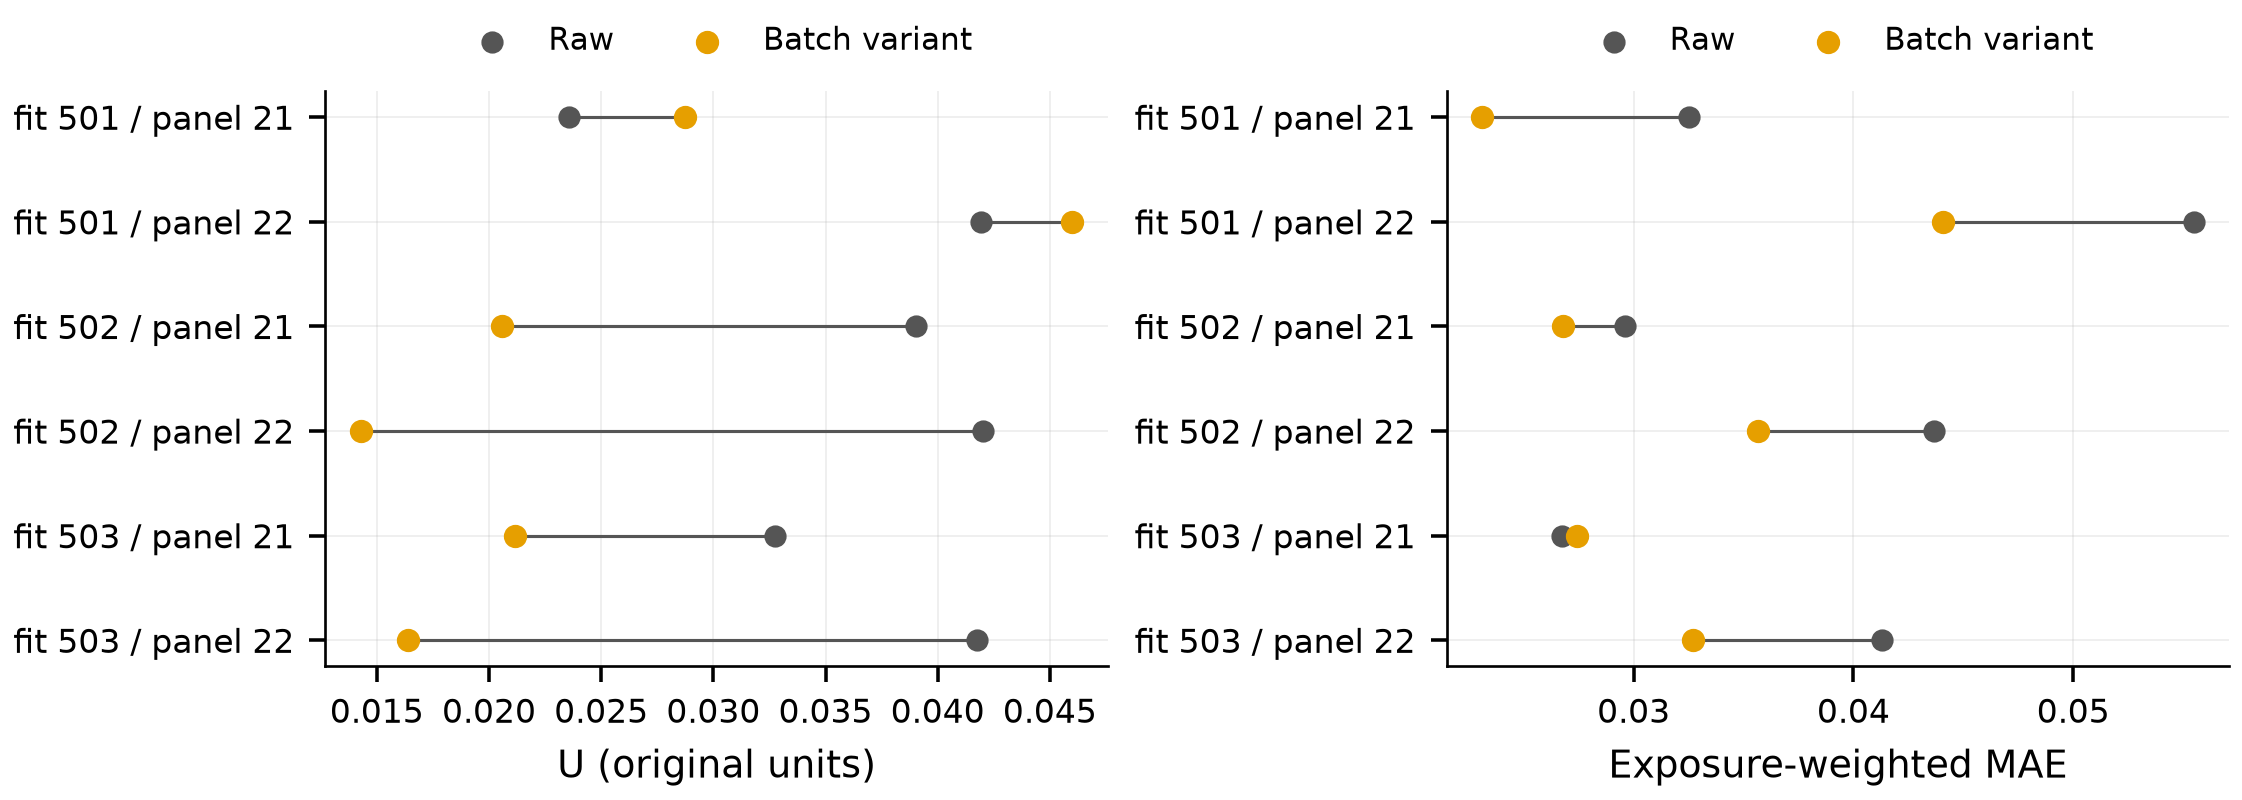

c:\DevSpace\PyDevspace\RL\RL_project\figure_assets\main\calibration_descriptive_1_part1.png

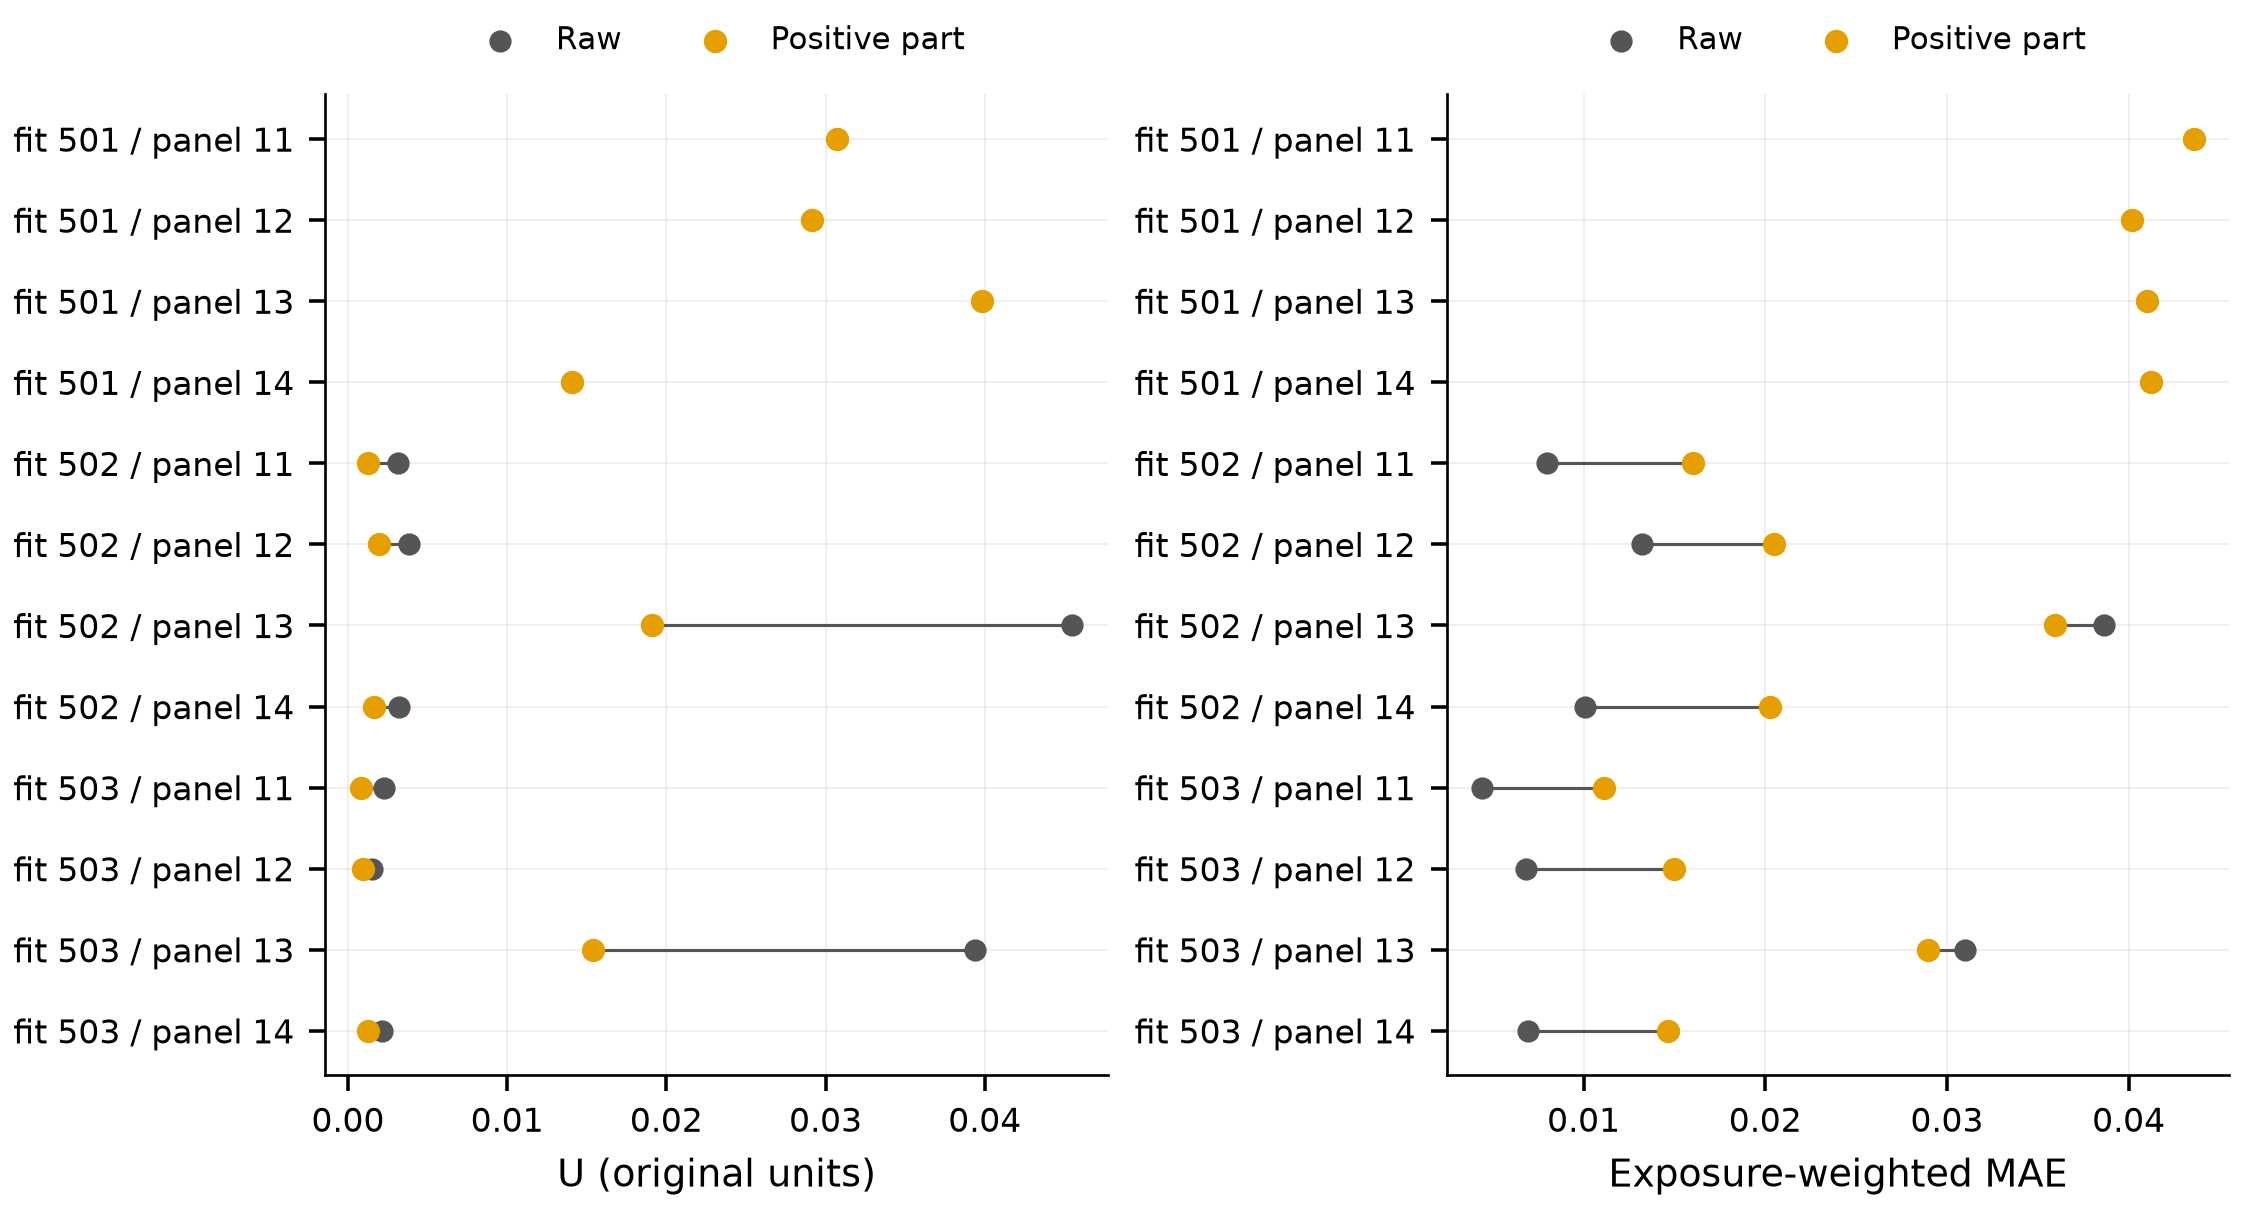

c:\DevSpace\PyDevspace\RL\RL_project\figure_assets\main\calibration_descriptive_2_part1.png

Unavailable families: [{'id': 'proxy_reliability', 'reason': 'No exact-ID matched actual audited labels; proxy predictions alone are insufficient.'}, {'id': 'batch_residual', 'reason': 'No actual audited truth/prediction pairs with batch sizes.'}, {'id': 'calibration_tradeoff', 'reason': 'No same-model scoped calibration rows with nonzero raw U/EWMAE denominators.'}, {'id': 'formal_main_results', 'reason': 'Contract v1 supplies no authoritative full-gate schema proving frozen reference, complete audited policy risk, verification, all required seeds, and acceptance. Developer/pilot evidence is not promoted to formal results.'}]


In [ ]:
if manifest is None:
    print('No registered figures are available')
else:
    selected_figures = [f for f in manifest['figures'] if not FIGURE_IDS or f['id'] in FIGURE_IDS]
    unknown = set(FIGURE_IDS) - {f['id'] for f in manifest['figures']}
    if unknown:
        print('Unregistered figure IDs:', sorted(unknown))
    if len(selected_figures) > 24:
        raise ValueError('Select at most 24 figures per display')
    for figure in selected_figures:
        relative = PurePosixPath(figure['files']['png'])
        image_path = (asset_root / str(relative)).resolve()
        if relative.is_absolute() or any(p == '..' or ':' in p or '\\' in p for p in relative.parts) or not image_path.is_relative_to((asset_root / 'main').resolve()) or image_path.suffix != '.png':
            raise ValueError('Unconfined PNG asset path')
        if not image_path.is_file():
            print('Missing existing PNG:', figure['id'])
            continue
        if image_path.stat().st_size > 16 * 1024 * 1024:
            raise ValueError('PNG exceeds the 16 MiB display limit')
        display(HTML('<h3>' + escape(figure['title']) + '</h3>'))
        display(Image(filename=str(image_path), width=FIGURE_DISPLAY_WIDTH))
        display(FileLink(str(image_path.relative_to(PROJECT_ROOT))))
        details = '<details><summary>Caption and provenance</summary>'
        for label, value in [('Figure snapshot', manifest['snapshot_id']), ('Scope', figure['scope']), ('Caption', figure['caption']), ('Description', figure['description']), ('Source runs', ', '.join(figure['source_run_ids']))]:
            details += '<p><b>' + escape(label) + ':</b> ' + escape(str(value)) + '</p>'
        display(HTML(details + '</details>'))
    print('Unavailable families:', manifest['skipped'])

<a id="interactive-lab"></a>
## 6 · Embed the current interactive frontend

The black English **Cloud–Edge Lab** retains the State → Agent → Action → Environment → Reward loop, actual-client collaboration, seven-policy historical playback and linked outcome curves. The removed joint-action matrix, ranking and candidate preview are not reintroduced.

This cell invokes the already installed Vite CLI, not a custom server or helper file. It serves only `frontend/dist/` on `127.0.0.1`. A PowerShell parent enforces a finite lease and process-tree cleanup, independently of the notebook kernel. If inline embedding is blocked, use the printed local link. Set `FRONTEND_URL` to attach to an already running frontend without starting or stopping it.

In [6]:
import shutil, socket, subprocess, time, uuid
from urllib.request import urlopen
import psutil

if type(PREVIEW_LEASE_SECONDS) is not int or not 10 <= PREVIEW_LEASE_SECONDS <= 3600:
    raise ValueError('Preview lease must be between 10 and 3600 seconds')
active_url = FRONTEND_URL.strip()
if not active_url and START_PREVIEW:
    previous = globals().get('preview_handle')
    if previous is not None and previous.poll() is None:
        active_url = preview_url
    else:
        frontend_dir = PROJECT_ROOT / 'frontend'
        vite_cli = frontend_dir / 'node_modules/vite/bin/vite.js'
        node, powershell = shutil.which('node'), shutil.which('pwsh') or shutil.which('powershell')
        if not node or not powershell or not vite_cli.is_file() or not (frontend_dir / 'dist/index.html').is_file():
            raise RuntimeError('Existing Node/Vite build and PowerShell are required; alternatively set FRONTEND_URL')
        with socket.socket() as probe:
            probe.bind(('127.0.0.1', 0))
            port = probe.getsockname()[1]
        preview_url = active_url = f'http://127.0.0.1:{port}/'
        preview_log_dir = frontend_dir / '.logs'
        preview_log_dir.mkdir(exist_ok=True)
        preview_log = preview_log_dir / ('notebook-preview-' + uuid.uuid4().hex)
        quoted = [str(p).replace("'", "''") for p in (node, vite_cli, frontend_dir, preview_log)]
        command = (f"$ErrorActionPreference='Stop'; $p=Start-Process -FilePath '{quoted[0]}' -ArgumentList @('{quoted[1]}','preview','--host','127.0.0.1','--port','{port}','--strictPort') -WorkingDirectory '{quoted[2]}' -RedirectStandardOutput '{quoted[3]}.out.log' -RedirectStandardError '{quoted[3]}.err.log' -PassThru; "
                   f"try {{ if ($p.WaitForExit({PREVIEW_LEASE_SECONDS * 1000})) {{ exit $p.ExitCode }} }} finally {{ if (-not $p.HasExited) {{ taskkill /PID $p.Id /T /F | Out-Null; $p.WaitForExit(5000) | Out-Null }} }}")
        preview_handle = subprocess.Popen([powershell, '-NoProfile', '-NonInteractive', '-Command', command], stdin=subprocess.DEVNULL, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        preview_expires_at = time.monotonic() + PREVIEW_LEASE_SECONDS
        deadline = time.monotonic() + 10
        ready = False
        while time.monotonic() < deadline and preview_handle.poll() is None:
            try:
                with urlopen(active_url, timeout=1) as response:
                    ready = response.status == 200 and b'Cloud' in response.read()
                if ready:
                    break
            except OSError:
                pass
            time.sleep(0.1)
        if not ready:
            if preview_handle.poll() is None:
                parent = psutil.Process(preview_handle.pid)
                owned = [*parent.children(recursive=True), parent]
                for process in owned:
                    try:
                        process.kill()
                    except psutil.NoSuchProcess:
                        pass
                psutil.wait_procs(owned, timeout=3)
            raise RuntimeError(f'Preview did not become ready within 10 seconds; logs: {preview_log}')
if active_url:
    display(HTML('<p><a target="_blank" rel="noopener" href="' + escape(active_url, quote=True) + '">Open Cloud–Edge Lab</a></p>'))
    print('Preview URL:', active_url)
    if not FRONTEND_URL:
        print('Lease remaining (s):', max(0, round(preview_expires_at - time.monotonic())))
    display(IFrame(src=active_url, width='100%', height=FRONTEND_HEIGHT))
else:
    print('Preview disabled; existing figures and recorded tables remain available')

Preview URL: http://127.0.0.1:54332/
Lease remaining (s): 1799


<a id="preview-lifecycle"></a>
## 7 · Stop the notebook-owned preview

Set `STOP_PREVIEW=True` and run the cell below to stop only the preview process owned by this kernel, together with its child processes. URLs supplied through `FRONTEND_URL` are not stopped. Otherwise, the preview stops at lease expiry or when the kernel shuts down its children.

After a kernel restart, rerun sections 1 and 6 to open a new bounded preview. Use `FRONTEND_URL` only for a separately running service. To reread updated existing snapshots or assets, rerun sections 2–5. The notebook never refreshes data or renders images automatically.

In [ ]:
handle = globals().get('preview_handle')
if STOP_PREVIEW and handle is not None and handle.poll() is None:
    parent = psutil.Process(handle.pid)
    owned = [*parent.children(recursive=True), parent]
    for process in owned:
        try:
            process.kill()
        except psutil.NoSuchProcess:
            pass
    _, survivors = psutil.wait_procs(owned, timeout=3)
    if survivors:
        raise RuntimeError('Owned preview process-tree cleanup did not finish')
    print('Notebook-owned preview stopped')
else:
    print('Owned preview:', 'running' if handle is not None and handle.poll() is None else 'not running')